# 10 — Apprentissage automatique avec scikit-learn

L'apprentissage **supervisé** consiste à apprendre une relation à partir
d'exemples étiquetés. On dispose d'une matrice de **variables d'entrée**
`X` (les mesures des capteurs) et d'une **cible** `y` (la grandeur à
prédire). Le modèle apprend sur une partie des données, puis on mesure sa
capacité à généraliser sur des données qu'il n'a jamais vues.

**Objectifs du notebook**

- distinguer régression (prédire un nombre) et classification (prédire une classe) ;
- découper les données en ensemble d'entraînement et ensemble de test ;
- évaluer un modèle avec MAE, RMSE, R², exactitude, précision et rappel ;
- lire une matrice de confusion et interpréter des coefficients ;
- comprendre le surapprentissage et l'intérêt de la validation croisée.

**Prérequis** : NumPy, Pandas (notebook 08) et notions de statistiques.
Aucune connaissance de scikit-learn n'est nécessaire.


## Utilisation en ligne (Google Colab)

Cette cellule ne fait rien sur votre ordinateur. Dans Google Colab, elle
clone le dépôt public (données comprises) et place le notebook à sa racine,
afin que les chemins `data/...` fonctionnent. Exécutez-la en premier.


In [1]:
import os  # manipulation des chemins et du dossier courant
import subprocess  # lance la commande git clone
import sys  # permet de détecter l'environnement Colab

DEPOT = "https://github.com/VladdKid/python-electronique-ia.git"  # adresse publique du cours
DOSSIER = "python-electronique-ia"  # dossier local créé par le clone

if "google.colab" in sys.modules and not os.path.isdir("data"):  # uniquement dans Colab, si les données manquent
    if not os.path.isdir(DOSSIER):  # évite de cloner deux fois le dépôt
        subprocess.run(["git", "clone", "--depth", "1", DEPOT, DOSSIER], check=True)  # télécharge le cours
    os.chdir(DOSSIER)  # se place à la racine du dépôt cloné
    print(f"Dépôt prêt : {os.getcwd()}")  # confirme le dossier de travail


## 1. Les bibliothèques et le vocabulaire

`scikit-learn` fournit tous les modèles avec la même interface : `fit` pour
apprendre, `predict` pour prédire. Un **Pipeline** enchaîne un prétraitement
et un modèle comme un seul objet, ce qui évite d'oublier une étape lors du
passage en production.


In [2]:
import numpy as np  # calculs numériques (logarithme, racine carrée)
import pandas as pd  # lecture des fichiers CSV et tableaux de résultats
import matplotlib.pyplot as plt  # tracés de nuages de points
from sklearn.model_selection import train_test_split, cross_val_score  # découpage et validation croisée
from sklearn.linear_model import LinearRegression, LogisticRegression  # régression et classification linéaires
from sklearn.preprocessing import PolynomialFeatures, StandardScaler  # variables polynomiales et normalisation
from sklearn.pipeline import Pipeline  # enchaînement prétraitement + modèle
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score  # métriques de régression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report  # métriques de classification


## 2. Partie A — Régression : calibrer une thermistance

Une thermistance CTN voit sa résistance **diminuer** quand la température
augmente. La table de calibration contient 150 couples
résistance/température. La variable d'entrée `X` doit être un tableau à deux
dimensions, d'où le double crochet `[["resistance_ohm"]]` ; la cible `y` est
un vecteur de températures.


In [3]:
calibration = pd.read_csv("data/calibration_thermistance.csv")  # charge la table de calibration de la CTN
print(calibration.head())  # affiche les 5 premières lignes : la résistance décroît
calibration.describe().round(1)  # plage de températures et de résistances


   temperature_C  resistance_ohm
0          -10.0         57552.8
1           -9.4         56480.6
2           -8.8         52837.4
3           -8.2         53663.6
4           -7.6         51297.1


,temperature_C,resistance_ohm
count,150.0,150.0
mean,35.0,12853.2
std,26.2,14139.0
min,-10.0,1274.0
25%,12.5,2679.4
50%,35.0,6582.6
75%,57.5,17798.1
max,80.0,57552.8


On sépare la résistance (entrée) de la température (sortie). Le format
`(150, 1)` de `X` est imposé par scikit-learn : les lignes sont les mesures,
les colonnes les variables d'entrée.


In [4]:
X = calibration[["resistance_ohm"]].to_numpy()  # variable d'entrée : résistance en ohms, tableau (150, 1)
y = calibration["temperature_C"].to_numpy()  # cible : température en degrés Celsius
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # 80 % entraînement, 20 % test
print(f"Entraînement : {X_train.shape[0]} mesures | Test : {X_test.shape[0]} mesures")  # vérifie le découpage


Entraînement : 120 mesures | Test : 30 mesures


`LinearRegression` ajuste une droite `T = a × R + b`. `fit` calcule `a` et
`b` sur l'ensemble d'entraînement ; `predict` applique la formule aux
résistances de test. On ne touche jamais aux données de test pendant
l'apprentissage : elles servent uniquement de juge impartial.


In [5]:
modele_lineaire = LinearRegression()  # crée un modèle de régression linéaire (une droite)
modele_lineaire.fit(X_train, y_train)  # ajuste les coefficients sur les données d'entraînement
prediction_lineaire = modele_lineaire.predict(X_test)  # prédit la température des mesures de test


Trois métriques complémentaires : la **MAE** est l'erreur moyenne en °C,
facile à interpréter ; la **RMSE** pénalise davantage les grosses erreurs ;
le **R²** est la fraction de variance expliquée (1 = parfait, 0 = aussi bien
que prédire la moyenne). Un R² de 0,75 laisse donc un quart de la variance
inexpliqué : la droite est trop rigide pour une CTN.


In [6]:
mae_lineaire = mean_absolute_error(y_test, prediction_lineaire)  # erreur absolue moyenne, en °C
rmse_lineaire = root_mean_squared_error(y_test, prediction_lineaire)  # racine de l'erreur quadratique moyenne
r2_lineaire = r2_score(y_test, prediction_lineaire)  # coefficient de détermination R²
print(f"Linéaire : MAE = {mae_lineaire:.2f} °C | RMSE = {rmse_lineaire:.2f} °C | R² = {r2_lineaire:.3f}")  # affiche les trois métriques


Linéaire : MAE = 12.02 °C | RMSE = 13.27 °C | R² = 0.748


Le nuage de points confronte prédiction et mesure. Plus les points sont
proches de la diagonale, meilleur est le modèle ; un écart systématique aux
extrémités trahit une relation non linéaire.


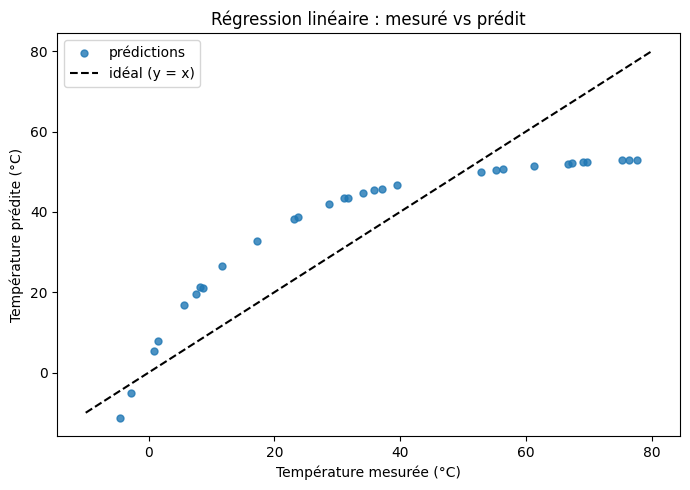

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))  # crée la figure du nuage de points
ax.scatter(y_test, prediction_lineaire, s=25, alpha=0.8, label="prédictions")  # température réelle en abscisse, prédite en ordonnée
ax.plot([y.min(), y.max()], [y.min(), y.max()], "k--", label="idéal (y = x)")  # droite où prédiction = mesure
ax.set(xlabel="Température mesurée (°C)", ylabel="Température prédite (°C)", title="Régression linéaire : mesuré vs prédit")  # titres et axes
ax.legend()  # affiche la légende
plt.tight_layout()  # ajuste les marges
plt.show()  # affiche la figure


Les points s'écartent de la diagonale aux extrémités : la relation est
courbe. Deux remèdes classiques : ajouter des variables polynomiales
(`R²`, `R`), ou utiliser une variable issue de la physique du composant.
La loi de la CTN s'écrit approximativement `T ≈ B / ln(R/R0) - 273,15` :
`1/ln(R)` est donc presque linéaire en température. C'est l'**ingénierie de
variables**, souvent plus efficace que d'ajouter de la complexité au modèle.


In [8]:
modele_polynomial = Pipeline([  # enchaîne la création de variables et la régression
    ("polynome", PolynomialFeatures(degree=2)),  # ajoute R² et R comme variables d'entrée
    ("regression", LinearRegression()),  # régression linéaire sur ces nouvelles variables
])  # fin de la définition du pipeline
modele_polynomial.fit(X_train, y_train)  # entraîne le pipeline complet
prediction_polynomiale = modele_polynomial.predict(X_test)  # prédit avec le modèle quadratique
r2_polynomial = r2_score(y_test, prediction_polynomiale)  # R² du modèle quadratique
mae_polynomial = mean_absolute_error(y_test, prediction_polynomiale)  # MAE du modèle quadratique
print(f"Polynôme degré 2 : MAE = {mae_polynomial:.2f} °C | R² = {r2_polynomial:.3f}")  # affiche les métriques


Polynôme degré 2 : MAE = 7.06 °C | R² = 0.909


Le polynôme améliore le score, mais il reste une approximation statistique.
Testons maintenant la variable issue de la loi physique de la CTN : une
seule colonne, choisie pour la bonne raison.


In [9]:
X_log_train = (1.0 / np.log(X_train)).reshape(-1, 1)  # variable physique 1/ln(R), remise en colonne
X_log_test = (1.0 / np.log(X_test)).reshape(-1, 1)  # même transformation pour les données de test
modele_log = LinearRegression()  # régression linéaire sur cette seule variable
modele_log.fit(X_log_train, y_train)  # ajuste la droite T = a × 1/ln(R) + b
prediction_log = modele_log.predict(X_log_test)  # prédit les températures de test
r2_log = r2_score(y_test, prediction_log)  # R² du modèle physique
mae_log = mean_absolute_error(y_test, prediction_log)  # MAE du modèle physique
print(f"Modèle 1/ln(R) : MAE = {mae_log:.2f} °C | R² = {r2_log:.3f}")  # affiche les métriques


Modèle 1/ln(R) : MAE = 0.79 °C | R² = 0.999


Pour comparer honnêtement les approches, on rassemble les trois scores dans
un tableau. La même métrique, calculée sur le même ensemble de test, rend la
comparaison directe.


In [10]:
comparaison = pd.DataFrame({"modèle": ["linéaire", "polynôme 2", "1/ln(R)"],  # noms des trois modèles
                            "MAE (°C)": [mae_lineaire, mae_polynomial, mae_log],  # erreurs absolues moyennes
                            "R²": [r2_lineaire, r2_polynomial, r2_log]})  # coefficients de détermination
comparaison.round(3)  # affiche le tableau arrondi


,modèle,MAE (°C),R²
0,linéaire,12.021,0.748
1,polynôme 2,7.057,0.909
2,1/ln(R),0.794,0.999


Le modèle `1/ln(R)` atteint un R² proche de 0,999 avec un seul coefficient :
il respecte la physique du capteur. Le polynôme de degré 2 fait mieux que la
droite mais reste approximatif. Attention au **surapprentissage** : un
polynôme de degré très élevé collerait parfaitement aux points
d'entraînement et prédirait mal les nouveaux. La règle reste de comparer les
scores sur l'ensemble de test, jamais sur l'ensemble d'entraînement.


## 3. Partie B — Classification : détecter un défaut moteur

Le second jeu de données décrit un moteur avec quatre capteurs : vibration
RMS, température, courant absorbé et régime de rotation. La cible `defaut`
vaut 1 si le moteur est défaillant. C'est un problème de **classification
binaire** : le modèle doit séparer deux populations, pas prédire un nombre.


In [11]:
maintenance = pd.read_csv("data/maintenance_capteurs.csv")  # charge les mesures étiquetées du moteur
print(maintenance.head())  # affiche les premières mesures avec leur étiquette
maintenance["defaut"].value_counts(normalize=True).round(3)  # proportion de moteurs défaillants


   vibration_rms  temperature_C  courant_A  regime_tr_min  defaut
0          0.455           58.9       3.23         1430.0       0
1          0.438           69.3       3.37         1369.0       0
2          0.391           48.6       3.21         1411.0       0
3          0.928           70.6       3.90         1232.0       1
4          0.451           60.0       3.26         1417.0       1


defaut
0    0.688
1    0.312
Name: proportion, dtype: float64

`train_test_split(..., stratify=y)` conserve la même proportion de défauts
dans les deux ensembles : sans cela, un tirage malchanceux pourrait placer
presque tous les défauts dans l'ensemble d'entraînement. `random_state`
fixe le tirage pour rendre le résultat reproductible.


In [12]:
features = ["vibration_rms", "temperature_C", "courant_A", "regime_tr_min"]  # les quatre variables d'entrée
X_defaut = maintenance[features]  # tableau des variables, avec le nom des colonnes
y_defaut = maintenance["defaut"].to_numpy()  # cible binaire : 0 = sain, 1 = défaillant
X_app, X_test_defaut, y_app, y_test_defaut = train_test_split(X_defaut, y_defaut, test_size=0.2, random_state=42, stratify=y_defaut)  # découpage stratifié 80/20
print(f"Apprentissage : {X_app.shape[0]} mesures | Test : {X_test_defaut.shape[0]} mesures")  # vérifie le découpage


Apprentissage : 1280 mesures | Test : 320 mesures


La régression logistique calcule une combinaison linéaire des capteurs puis
la transforme en probabilité entre 0 et 1. La **normalisation** est
indispensable ici : la vibration vaut environ 0,5 alors que le régime vaut
1450. Sans `StandardScaler`, le régime dominerait artificiellement et la
descente de gradient convergerait mal. Le pipeline applique la
normalisation en apprentissage **et** en prédiction, avec les mêmes
paramètres.


In [13]:
classifieur = Pipeline([  # normalisation puis régression logistique
    ("normalisation", StandardScaler()),  # ramène chaque capteur à moyenne 0 et écart-type 1
    ("logistique", LogisticRegression(max_iter=1000)),  # modèle linéaire qui estime une probabilité
])  # fin du pipeline
classifieur.fit(X_app, y_app)  # entraîne le pipeline sur les données d'apprentissage
prediction_defaut = classifieur.predict(X_test_defaut)  # classe prédite (0 ou 1) pour chaque mesure de test


L'**exactitude** (accuracy) est la proportion de bonnes prédictions. La
**matrice de confusion** détaille les erreurs : lignes = classe réelle,
colonnes = classe prédite. La **précision** répond à « parmi les alarmes
déclenchées, combien sont justes ? » ; le **rappel** à « parmi les vrais
défauts, combien ont été détectés ? ». Un rappel faible signifie des pannes
manquées, souvent plus grave qu'une fausse alarme.


In [14]:
exactitude = accuracy_score(y_test_defaut, prediction_defaut)  # proportion de classes correctement prédites
matrice = confusion_matrix(y_test_defaut, prediction_defaut)  # lignes = réel, colonnes = prédit
print(f"Exactitude : {exactitude:.3f}")  # affiche le taux de bonnes prédictions
print(matrice)  # affiche la matrice de confusion
print(classification_report(y_test_defaut, prediction_defaut, target_names=["sain", "défaillant"], digits=3))  # précision, rappel et F1 par classe


Exactitude : 0.928
[[213   7]
 [ 16  84]]
              precision    recall  f1-score   support

        sain      0.930     0.968     0.949       220
  défaillant      0.923     0.840     0.880       100

    accuracy                          0.928       320
   macro avg      0.927     0.904     0.914       320
weighted avg      0.928     0.928     0.927       320



Un score élevé ne doit pas masquer les erreurs : lisez toujours la matrice
de confusion. Ce jeu contient volontairement **3 % d'étiquettes erronées**,
comme un vrai carnet de maintenance mal rempli. Aucun modèle ne peut donc
être parfait, et un faux négatif (défaut manqué) coûte plus cher qu'une
fausse alarme. La **validation croisée** refait cinq découpages différents :
si le score reste stable, le résultat ne dépend pas d'un tirage particulier.


In [15]:
scores_cv = cross_val_score(classifieur, X_defaut, y_defaut, cv=5)  # cinq découpages entraînement/test
print(f"Validation croisée : {scores_cv.mean():.3f} ± {scores_cv.std():.3f}")  # moyenne et écart-type des cinq scores


Validation croisée : 0.941 ± 0.013


Les coefficients sont lisibles car les variables sont normalisées : un
coefficient positif signifie que le capteur **augmente** le risque de
défaillance, un coefficient négatif qu'il le diminue. La vibration arrive en
tête, le régime élevé est protecteur : cela correspond au bon sens mécanique.


In [16]:
coefficients = pd.Series(classifieur.named_steps["logistique"].coef_[0], index=features)  # un coefficient par capteur
coefficients.sort_values(ascending=False).round(3)  # classe les capteurs par contribution au risque


vibration_rms    2.008
temperature_C    0.863
courant_A        0.637
regime_tr_min   -0.970
dtype: float64

Enfin, on utilise le modèle sur une mesure nouvelle. `predict` renvoie la
classe, `predict_proba` la probabilité associée. C'est cette probabilité qui
permet de régler le seuil d'alarme selon le coût relatif d'une panne manquée
et d'une fausse alarme.


In [17]:
nouvelle_mesure = {"vibration_rms": 1.15, "temperature_C": 76.0, "courant_A": 3.95, "regime_tr_min": 1240.0}  # relevé d'un moteur suspect
mesure_df = pd.DataFrame([nouvelle_mesure])  # transforme le dictionnaire en tableau d'une ligne
classe = classifieur.predict(mesure_df)[0]  # classe prédite pour cette mesure
probabilite = classifieur.predict_proba(mesure_df)[0, 1]  # probabilité de défaillance
print(f"Classe prédite : {classe} | Probabilité de défaillance : {probabilite:.3f}")  # affiche le diagnostic


Classe prédite : 1 | Probabilité de défaillance : 1.000


## 4. À vous de jouer

Complétez les cellules suivantes. Les commentaires indiquent les étapes ;
réutilisez les variables `X_app`, `y_app`, `X_test_defaut`, `y_test_defaut`.


**Exercice 1** — Remplacez la régression logistique par une forêt aléatoire
(`RandomForestClassifier(n_estimators=200, random_state=42)`) et comparez
l'exactitude. Un modèle plus complexe fait-il toujours mieux ? La
normalisation est-elle encore utile ?


In [18]:
# TODO : importez RandomForestClassifier depuis sklearn.ensemble

# TODO : construisez un Pipeline avec StandardScaler et le classifieur forêt

# TODO : entraînez-le sur X_app, y_app puis calculez l'exactitude sur le test

# TODO : comparez avec l'exactitude de la régression logistique


**Exercice 2** — Refaites le découpage avec `test_size=0.1`, puis avec
`test_size=0.4`. Affichez à chaque fois l'exactitude. Que remarquez-vous sur
la variabilité du score quand l'ensemble de test est petit ?


In [19]:
# TODO : refaites train_test_split avec test_size=0.1 et stratify=y_defaut

# TODO : entraînez le classifieur et affichez l'exactitude

# TODO : répétez avec test_size=0.4

# TODO : commentez l'effet de la taille de l'ensemble de test


**Exercice 3** — Le seuil par défaut de `predict` est 0,5. Calculez les
prédictions avec un seuil de 0,9 à partir de `predict_proba`, puis affichez
la matrice de confusion. Combien de défauts sont manqués ? Le compromis
précision/rappel est-il acceptable pour une maintenance industrielle ?


In [20]:
# TODO : récupérez les probabilités avec classifieur.predict_proba(...)[:, 1]

# TODO : créez les prédictions (proba >= 0.9).astype(int)

# TODO : affichez la matrice de confusion et le classification_report

# TODO : concluez sur le choix du seuil d'alarme


## 5. À retenir

- En apprentissage supervisé, `X` contient les mesures et `y` la grandeur à
  prédire ; on sépare toujours entraînement et test.
- Régression : MAE et RMSE en unités physiques, R² pour la variance expliquée.
- Classification : exactitude, précision, rappel et matrice de confusion.
- Le surapprentissage se détecte en comparant les scores d'entraînement et de
  test ; la validation croisée donne une estimation plus robuste.
- La normalisation est obligatoire quand les capteurs ont des échelles très
  différentes.
- Une variable issue de la physique (`1/ln(R)`) peut battre un modèle
  polynomial plus complexe.

**Notebook suivant** : `11 — Réseaux de neurones`. Les mêmes données
(`X`, `y`, découpage, normalisation) y seront réutilisées, mais le modèle
apprendra lui-même les variables pertinentes au lieu de les fournir à la main.
